# ESE5023 Assignment02

## 1. Significant earthquakes since 2150 B.C.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

Sig_Eqs = pd.read_csv(
    "earthquakes-2026-10-16_15-34-55_+0800.tsv",
    sep="\t",
    low_memory=False
)

### 1.1

In [4]:
top20 = (
    Sig_Eqs.groupby("Country")["Deaths"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

print(top20)

Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014438.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64


### 1.2

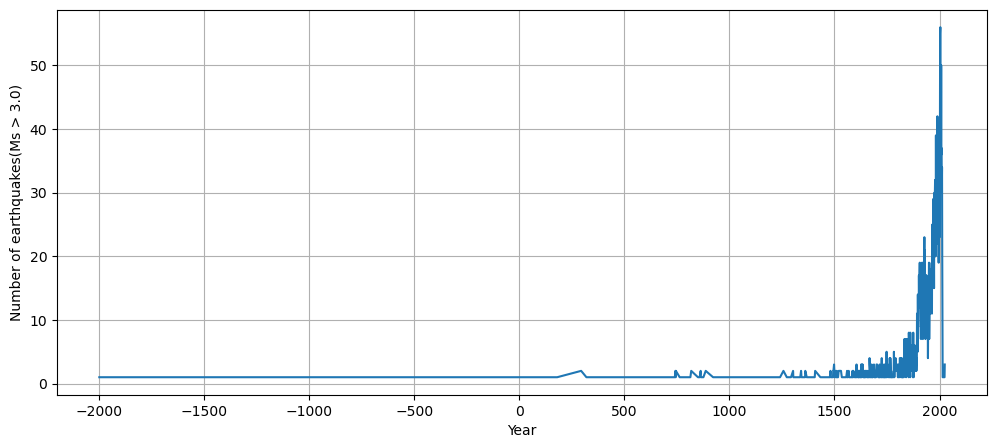

In [6]:
eq_over3 = Sig_Eqs[Sig_Eqs["Ms"] > 3.0]
annual_count = eq_over3.groupby("Year").size()

plt.figure(figsize=(12, 5))
plt.plot(annual_count.index, annual_count.values)
plt.xlabel("Year")
plt.ylabel("Number of earthquakes(Ms > 3.0)")
plt.grid()
plt.show()

### 1.3

In [7]:
def CountEq_LargestEq(country):
    country_data = Sig_Eqs[Sig_Eqs["Country"] == country]
    earthquake_count = len(country_data)

    if country_data["Mag"].notna().sum() == 0:
        largest_date = "No data"
        largest_location = "No data"
    else:
        largest = country_data.loc[country_data["Mag"].idxmax()]
        year = int(largest["Year"])
        month = "NA" if pd.isna(largest["Mo"]) else int(largest["Mo"])
        day = "NA" if pd.isna(largest["Dy"]) else int(largest["Dy"])
        largest_date = f"{year}-{month}-{day}"
        largest_location = largest["Location Name"]

    return earthquake_count, largest_date, largest_location


results = []

for country in Sig_Eqs["Country"].dropna().unique():
    count, date, location = CountEq_LargestEq(country)
    results.append([country, count, date, location])

results = pd.DataFrame(
    results,
    columns=["Country", "Earthquake_Count", "Largest_Earthquake_Date", "Location"]
).sort_values("Earthquake_Count", ascending=False)

results

,Country,Earthquake_Count,Largest_Earthquake_Date,Location
14,CHINA,626,1668-7-25,CHINA: SHANDONG PROVINCE
33,JAPAN,429,2011-3-11,JAPAN: HONSHU
73,INDONESIA,427,2004-12-26,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
7,IRAN,385,856-12-22,"IRAN: DAMGHAN, QUMIS"
9,TURKEY,359,1939-12-26,TURKEY: ERZINCAN
...,...,...,...,...
97,SIERRA LEONE,1,1795-5-20,SIERRA LEONE
109,SAINT VINCENT AND THE GRENADINES,1,No data,No data
134,CENTRAL AFRICAN REPUBLIC,1,1921-9-16,CENTRAL AFRICAN REPUBLIC: NOLA
107,BARBADOS,1,No data,No data


## 2. Air temperature in Shenzhen 1998–2022

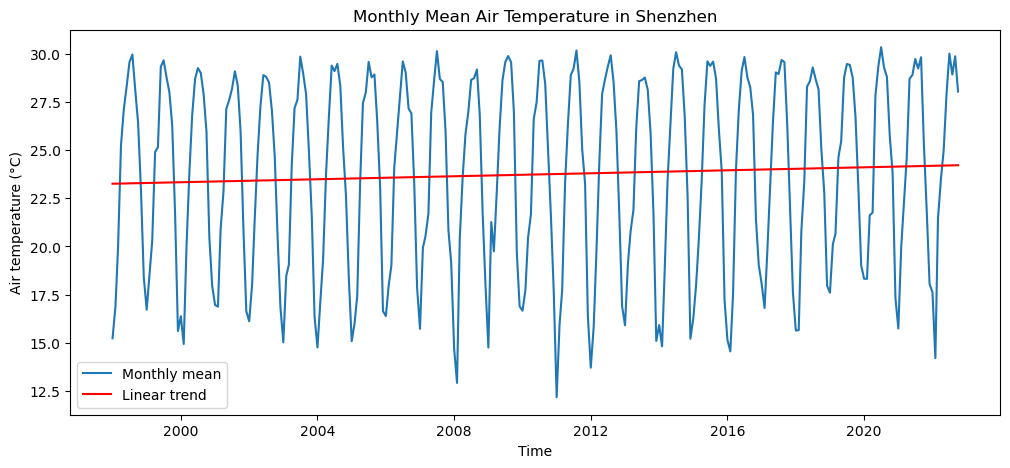

Slope: 0.03873600636339173 °C/year
P-value: 0.33910707287724584


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

weather = pd.read_csv("Baoan_Weather_1998_2022/Baoan_Weather_1998_2022.csv", low_memory=False)

tmp = weather["TMP"].str.split(",", expand=True)
weather["time"] = pd.to_datetime(weather["DATE"])
weather["temperature"] = pd.to_numeric(tmp[0], errors="coerce") / 10
weather["quality"] = tmp[1]

weather = weather[
    (tmp[0] != "+9999")
    & weather["quality"].isin(["0", "1", "4", "5", "9"])
]

monthly_temperature = (
    weather.set_index("time")["temperature"]
    .resample("MS")
    .mean()
)

x = (monthly_temperature.index - monthly_temperature.index[0]).days / 365.25
temperature_trend = stats.linregress(x, monthly_temperature.values)

plt.figure(figsize=(12, 5))
plt.plot(monthly_temperature.index, monthly_temperature.values, label="Monthly mean")
plt.plot(
    monthly_temperature.index,
    temperature_trend.intercept + temperature_trend.slope * x,
    color="red",
    label="Linear trend"
)
plt.xlabel("Time")
plt.ylabel("Air temperature (°C)")
plt.title("Monthly Mean Air Temperature in Shenzhen")
plt.legend()
plt.show()

print("Slope:", temperature_trend.slope, "°C/year")
print("P-value:", temperature_trend.pvalue)

## 3. Global collection of hurricanes

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(
    "ibtracs.ALL.list.v04r00/ibtracs.ALL.list.v04r00.csv",
    usecols=range(17),
    skiprows=[1],
    parse_dates=["ISO_TIME"],
    keep_default_na=False,
    na_values=[" ", "NOT_NAMED"],
    low_memory=False,
)

df["WMO_WIND"] = pd.to_numeric(df["WMO_WIND"], errors="coerce")
df["LAT"] = pd.to_numeric(df["LAT"], errors="coerce")
df["LON"] = pd.to_numeric(df["LON"], errors="coerce")

df.head()

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 03:00:00,NR,10.9000,80.3000,NaN,NaN,NaN,main,43,0.0,__________O___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,NaN,NaN,NaN,main,0,0.0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,NaN,NaN,NaN,main,0,0.0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,NaN,NaN,NaN,main,0,0.0,__________P___
4,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,NaN,NaN,NaN,main,0,0.0,__________O___


### 3.1

In [16]:
storms = (
    df.groupby("SID")
    .agg(NAME=("NAME", "first"), WMO_WIND=("WMO_WIND", "max"))
)

largest_10 = storms.sort_values("WMO_WIND", ascending=False).head(10)
largest_10[["NAME"]]

,NAME
SID,
2015293N13266,PATRICIA
1980214N11330,ALLEN
2019236N10314,DORIAN
1988253N12306,GILBERT
2005289N18282,WILMA
1935241N23291,None
1997253N12255,LINDA
2017242N16333,IRMA
1998295N12284,MITCH


### 3.2

In [17]:
strongest_20 = storms.sort_values("WMO_WIND", ascending=False).head(20)
strongest_20[["NAME", "WMO_WIND"]]

,NAME,WMO_WIND
SID,,
2015293N13266,PATRICIA,185.0
1980214N11330,ALLEN,165.0
2019236N10314,DORIAN,160.0
1988253N12306,GILBERT,160.0
2005289N18282,WILMA,160.0
1935241N23291,None,160.0
1997253N12255,LINDA,160.0
2017242N16333,IRMA,155.0
1998295N12284,MITCH,155.0


### 3.3

In [18]:
basin_counts = df.groupby("BASIN").size().sort_values(ascending=False)
basin_counts

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
dtype: int64

### 3.4

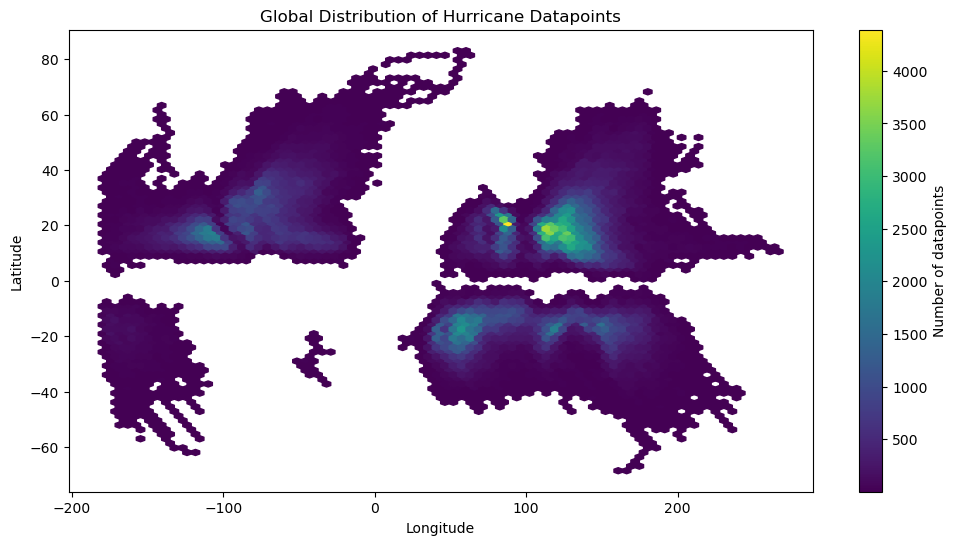

In [19]:
plt.figure(figsize=(12, 6))
plt.hexbin(df["LON"], df["LAT"], gridsize=80, mincnt=1, cmap="viridis")
plt.colorbar(label="Number of datapoints")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Distribution of Hurricane Datapoints")
plt.show()

### 3.5

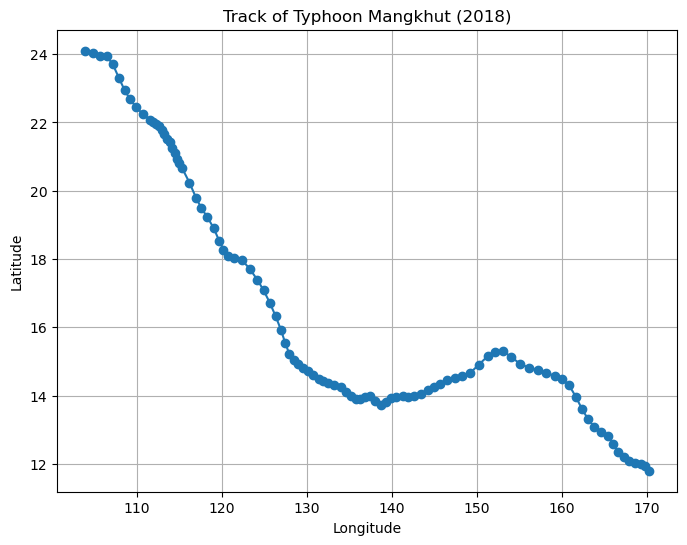

In [20]:
mangkhut = df[
    (df["SEASON"] == 2018)
    & (df["NAME"] == "MANGKHUT")
].sort_values("ISO_TIME")

plt.figure(figsize=(8, 6))
plt.plot(mangkhut["LON"], mangkhut["LAT"], marker="o")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Track of Typhoon Mangkhut (2018)")
plt.grid()
plt.show()

### 3.6

In [21]:
filtered = df[
    (df["ISO_TIME"].dt.year >= 1970)
    & df["BASIN"].isin(["WP", "EP"])
].copy()

filtered.head()

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,NaN,1006.0,tokyo,main,1088,1088.0,_OO___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,NaN,NaN,NaN,main,1109,1109.0,_PP___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,NaN,1002.0,tokyo,main,1143,1143.0,_OO___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,NaN,NaN,NaN,main,1171,1168.0,_PP___________
350398,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,NaN,998.0,tokyo,main,1182,1179.0,_OO___________


### 3.7

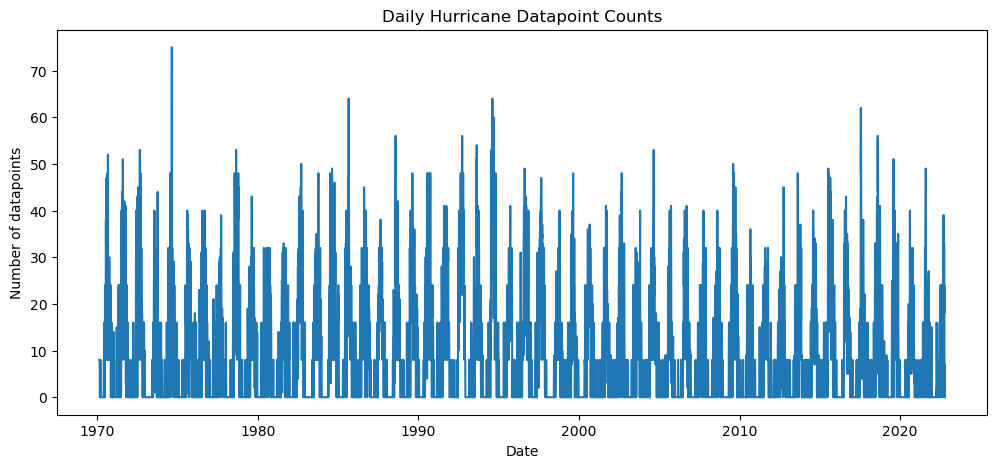

In [22]:
daily_counts = (
    filtered.set_index("ISO_TIME")
    .resample("D")
    .size()
    .rename("count")
)

plt.figure(figsize=(12, 5))
plt.plot(daily_counts.index, daily_counts.values)
plt.xlabel("Date")
plt.ylabel("Number of datapoints")
plt.title("Daily Hurricane Datapoint Counts")
plt.show()

### 3.8

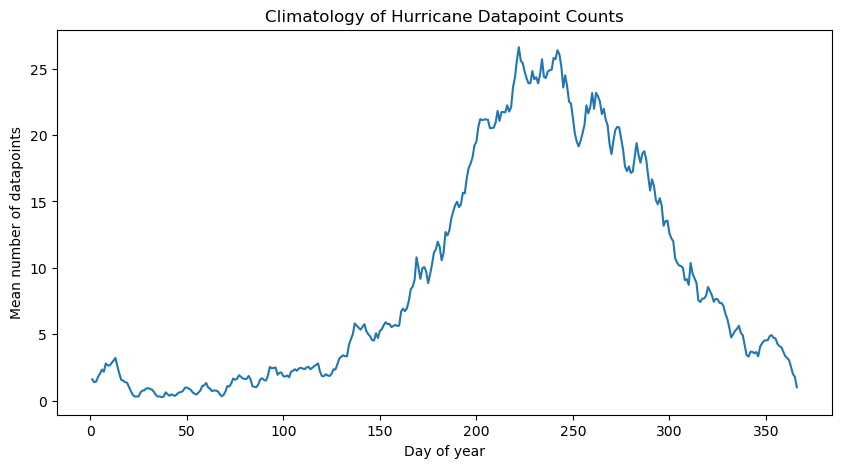

In [23]:
daily = daily_counts.to_frame()
daily["day_of_year"] = daily.index.dayofyear
climatology = daily.groupby("day_of_year")["count"].mean()

plt.figure(figsize=(10, 5))
plt.plot(climatology.index, climatology.values)
plt.xlabel("Day of year")
plt.ylabel("Mean number of datapoints")
plt.title("Climatology of Hurricane Datapoint Counts")
plt.show()

### 3.9

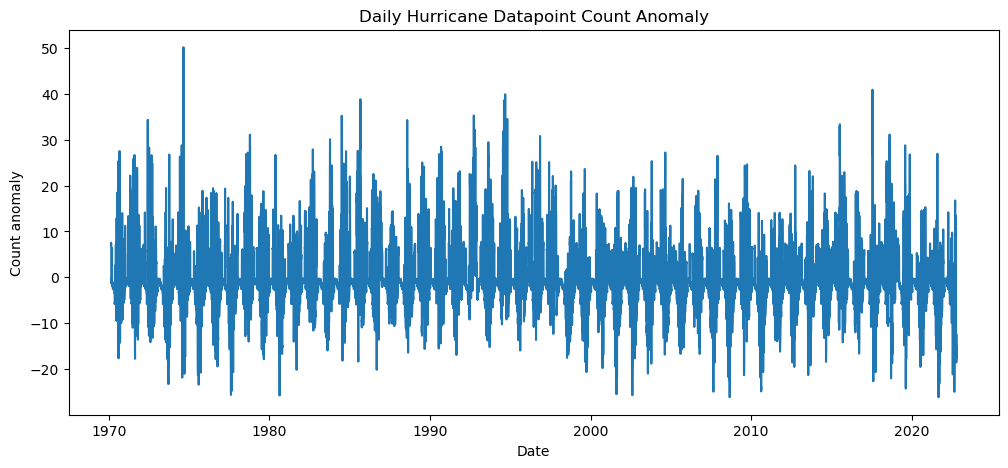

In [24]:
daily["climatology"] = daily["day_of_year"].map(climatology)
daily["anomaly"] = daily["count"] - daily["climatology"]

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily["anomaly"])
plt.xlabel("Date")
plt.ylabel("Count anomaly")
plt.title("Daily Hurricane Datapoint Count Anomaly")
plt.show()

### 3.10

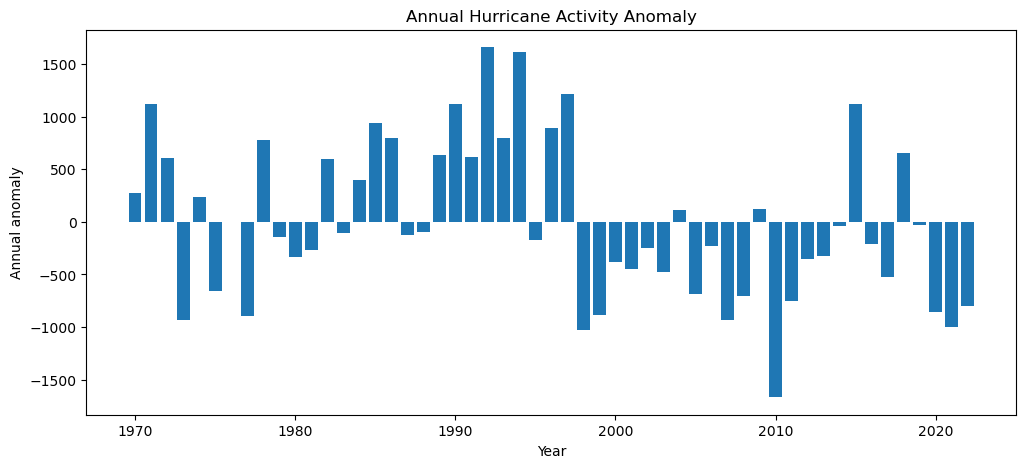

Highest anomaly years:
ISO_TIME
1992-01-01    1660.725327
1994-01-01    1611.725327
1997-01-01    1215.725327
1990-01-01    1121.725327
2015-01-01    1119.725327
Name: anomaly, dtype: float64
Lowest anomaly years:
ISO_TIME
2010-01-01   -1668.274673
1998-01-01   -1033.274673
2021-01-01   -1004.274673
2007-01-01    -935.274673
1973-01-01    -933.274673
Name: anomaly, dtype: float64


In [25]:
annual_anomaly = daily["anomaly"].resample("YS").sum()

plt.figure(figsize=(12, 5))
plt.bar(annual_anomaly.index.year, annual_anomaly.values)
plt.xlabel("Year")
plt.ylabel("Annual anomaly")
plt.title("Annual Hurricane Activity Anomaly")
plt.show()

print("Highest anomaly years:")
print(annual_anomaly.sort_values(ascending=False).head())
print("Lowest anomaly years:")
print(annual_anomaly.sort_values().head())

## 4. Explore a data set

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 4.1

In [4]:
data = pd.read_csv(
    "4_train_data.csv"
)

data = data.dropna().drop_duplicates()

feature_columns = data.columns.drop("label")
data = data[
    (data[feature_columns] >= 0).all(axis=1)
    & (data[feature_columns] <= 255).all(axis=1)
]

print(data.shape)
data.head()

(11603, 289)


,blue_00,green_00,red_00,NIR_00,SWIR1_00,LST_00,VV_00,VH_00,blue_01,green_01,...,VH_34,blue_35,green_35,red_35,NIR_35,SWIR1_35,LST_35,VV_35,VH_35,label
0,168,148,169,186,52,71,30,6,185,160,...,7,61,43,45,68,107,76,23,5,2
1,224,190,215,218,49,70,16,9,224,193,...,7,70,51,55,60,53,76,59,9,1
2,122,108,115,126,43,78,255,8,116,89,...,7,211,180,195,191,25,69,195,11,3
3,111,84,82,100,39,71,16,8,105,77,...,5,160,131,142,158,51,63,32,9,3
4,60,54,64,92,119,79,14,1,55,50,...,1,95,92,114,143,81,83,11,0,1


### 4.2

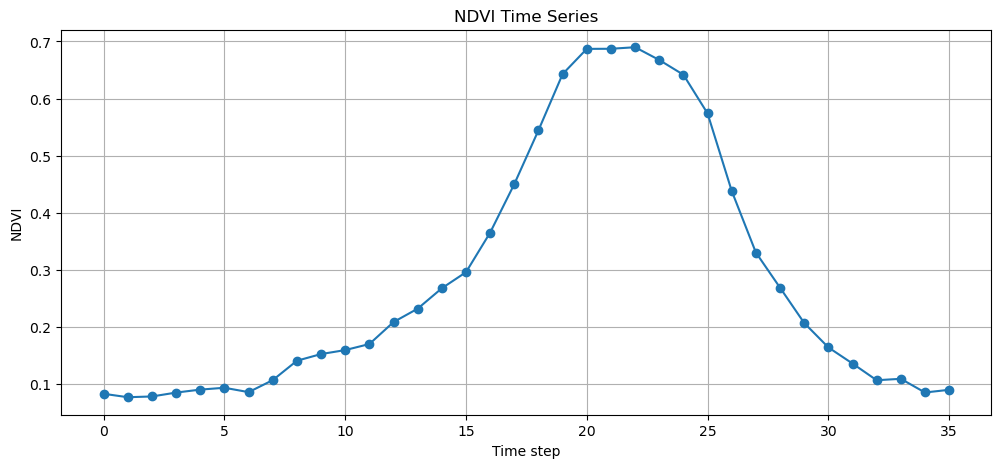

In [6]:
ndvi = pd.DataFrame()

for i in range(36):
    red = data[f"red_{i:02d}"]
    nir = data[f"NIR_{i:02d}"]
    ndvi[f"{i:02d}"] = (nir - red) / (nir + red)

mean_ndvi = ndvi.mean()

plt.figure(figsize=(12, 5))
plt.plot(range(36), mean_ndvi, marker="o")
plt.xlabel("Time step")
plt.ylabel("NDVI")
plt.title("NDVI Time Series")
plt.grid()
plt.show()

### 4.3

In [7]:
ndvi_values = ndvi.to_numpy().flatten()

statistics = pd.Series({
    "Mean": np.mean(ndvi_values),
    "Median": np.median(ndvi_values),
    "Standard deviation": np.std(ndvi_values),
    "Minimum": np.min(ndvi_values),
    "Maximum": np.max(ndvi_values)
})

print(statistics)

Mean                  0.283659
Median                0.190476
Standard deviation    0.263787
Minimum              -0.647059
Maximum               0.885057
dtype: float64
